# <font color="#0b486b">  FIT3181: Deep Learning (2026)</font>
***
*CE/Lecturer (Clayton):* **Dr [Trung Le](mailto:trunglm@monash.edu)** <br/>
*Lecturer (Clayton):* **Dr [Binh Nguyen](mailto:binh.nguyen1@monash.edu)** <br/>
*Lecturer (Malaysia):*  **Dr [Arghya Pal](mailto:arghya.pal@monash.edu)**, **Dr [Sailaja Rajanala](mailto:sailaja.rajanala@monash.edu)**, **Dr [Sicily Fung Fung Ting](mailto:ting.fung@monash.edu)** <br/>
*Head Tutor (Clayton):* **Mr [Minh Vo](mailto:minh.vo1@monash.edu)** (FIT3181), **Dr [Ruda Nie H](mailto:rudanie.h@monash.edu)** (FIT5215)

Faculty of Information Technology, Monash University, Australia
***

# <font color="#0b486b">  Student Information</font>
***
Surname: **Khoo**  <br/>
Firstname: **Lynn**    <br/>
Student ID: **34598901**    <br/>
Email: **lkho0011@student.monash.edu**    <br/>
Your tutorial time: **Thursday 14:00**    <br/>
***

# <font color="#0b486b">Deep Neural Networks</font>
### Due: <font color="red">11:55pm Sunday, 13 September 2026</font>  (Sunday)

#### <font color="red">Important note:</font> This is an **individual** assignment. It contributes **25%** to your final mark. Read the assignment instructions carefully.

## <font color="#0b486b">What to submit</font>

This assignment is to be completed individually and submitted to Moodle unit site. **By the due date, you are required to submit one  <font color="red; font-weight:bold">single zip file, named xxx_assignment01_solution.zip</font> where `xxx` is your student ID, to the corresponding Assignment (Dropbox) in Moodle**. You can use Google Colab to do Assigmnent 1 but you need to save it to an `*.ipynb` file to submit to the unit Moodle.

**More importantly, if you use Google Colab to do this assignment, you need to first make a copy of this notebook on your Google drive**.

***For example, if your student ID is <font color="red; font-weight:bold">123456</font>, then gather all of your assignment solution to folder, create a zip file named <font color="red; font-weight:bold">123456_assignment01_solution.zip</font> and submit this file.***

Within this zip folder, you **must** submit the following files:

1.	**Assignment01_solution.ipynb**:  this is your Python notebook solution source file.

2.	**Assignment01_output.html** or **Assignment01_output.pdf**: this is the output of your Python notebook solution *exported* in html or pdf format.

3.	Any **extra files or folder** needed to complete your assignment (e.g., images used in your answers).

Since the notebook is quite big to load and work together, one recommended option is to split solution into three parts and work on them seperately. In that case, replace **Assignment01_solution.ipynb** by three notebooks: **Assignment01_Part1_solution.ipynb**, **Assignment01_Part2_solution.ipynb** and **Assignment01_Part3_solution.ipynb**

**You can run your codes on Google Colab. In this case, you have to make a copy of your Google colab notebook including the traces and progresses of model training before submitting.**



## <font color="#0b486b">Part 2: Deep Neural Networks (DNN) </font>
<div style="text-align: right"><font color="red; font-weight:bold">[Total marks for this part: 25 points]</font></div>

The second part of this assignment is to demonstrate your basis knowledge in deep learning that you have acquired from the lectures and tutorials materials. Most of the contents in this assignment are drawn from **the tutorials covered from weeks 1 to 2**. Going through these materials before attempting this assignment is highly recommended.

In the second part of this assignment, you are going to work with the FashionMNIST dataset for the image recognition task. It has the exact same format as MNIST (70,000 grayscale images of 28 × 28 pixels each with 10 classes), but the images represent fashion items rather than handwritten digits, so each class is more diverse, and the problem is significantly more challenging than MNIST.

In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(1234)

**Load the Fashion MNIST using `torchvision`**

In [ ]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

train_dataset_orgin = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

print(train_dataset_orgin.data.shape, train_dataset_orgin.targets.shape)
print(test_dataset.data.shape, test_dataset.targets.shape)

# Flatten the data
train_dataset_orgin.data = train_dataset_orgin.data.reshape(-1, 28*28)
test_dataset.data = test_dataset.data.reshape(-1, 28*28)

print(train_dataset_orgin.data.shape, train_dataset_orgin.targets.shape)
print(test_dataset.data.shape, test_dataset.targets.shape)

N = len(train_dataset_orgin)
print(f"Number of training samples: {N}")
N_train = int(0.9*N)
N_val = N - N_train
print(f"Number of training samples: {N_train}")
print(f"Number of validation samples: {N_val}")

train_dataset, val_dataset = torch.utils.data.random_split(train_dataset_orgin, [N_train, N_val])


print(len(train_dataset))
print(len(val_dataset))


train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=1000, shuffle=False)

100%|██████████| 26.4M/26.4M [00:01<00:00, 18.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 312kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.67MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.7MB/s]

torch.Size([60000, 28, 28]) torch.Size([60000])
torch.Size([10000, 28, 28]) torch.Size([10000])
torch.Size([60000, 784]) torch.Size([60000])
torch.Size([10000, 784]) torch.Size([10000])
Number of training samples: 60000
Number of training samples: 54000
Number of validation samples: 6000
54000
6000


####  <font color="red">**Question 2.1:**</font> Write the code to visualize a mini-batch in `train_loader` including its images and labels.

<div style="text-align: right"> <font color="red">[5 points]</font> </div>

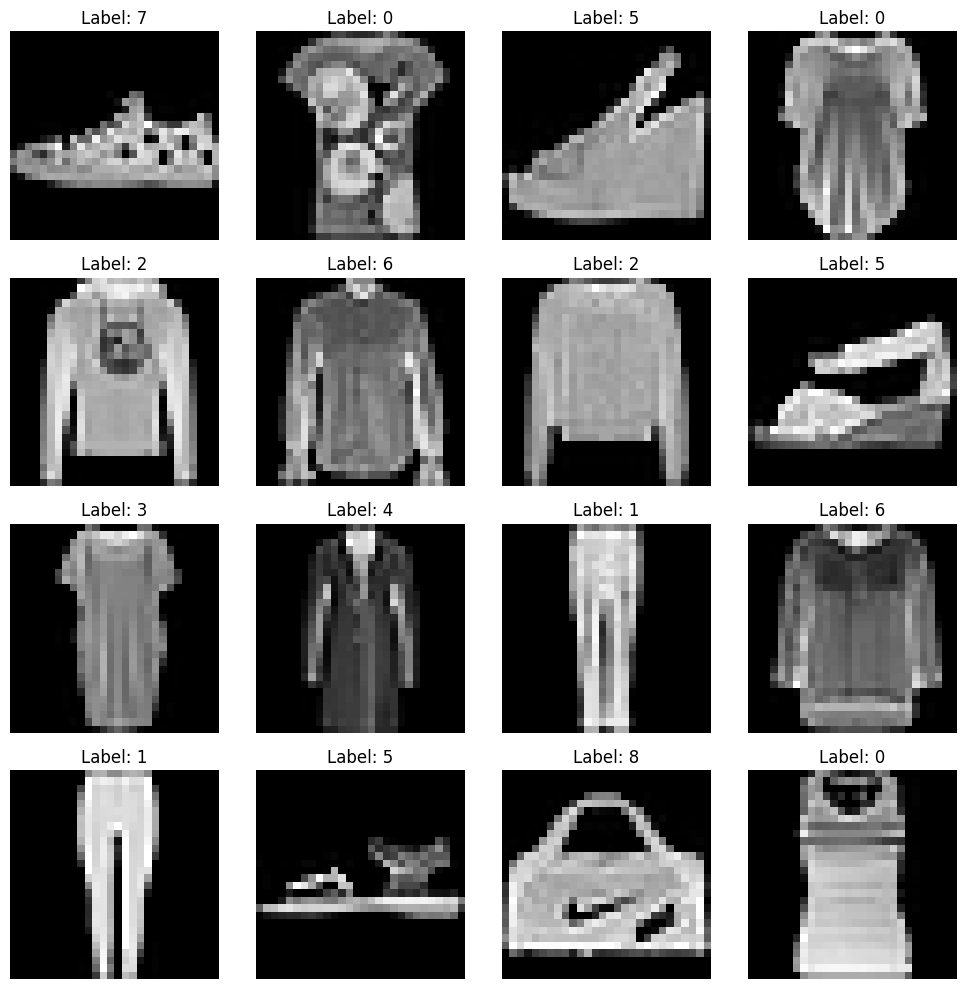

In [ ]:
#Your code here
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flatten()):
    image = images[i].reshape(28, 28)
    ax.imshow(image, cmap='gray')
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis('off')

plt.tight_layout()
plt.show()

####<font color="red">**Question 2.2:**</font> Write the code for the feed-forward neural net using PyTorch

<div style="text-align: right"> <font color="red">[5 points]</font> </div>

We now develop a feed-forward neural network with the architecture $784 \rightarrow 40(ReLU) \rightarrow 30(ReLU) \rightarrow 10(softmax)$. You can choose your own way to implement your network and an optimizer of interest. You should train model in $50$ epochs and evaluate the trained model on the test set.

In [ ]:
#Your code here
class FFN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = torch.nn.Linear(28 * 28, 40)
        self.fc2 = torch.nn.Linear(40, 30)
        self.fc3 = torch.nn.Linear(30, 10)

        self.relu = torch.nn.ReLU()

    def forward(self, x):
      x = x.view(x.size(0), -1)
      x = self.relu(self.fc1(x))
      x = self.relu(self.fc2(x))
      x = self.fc3(x)
      return x

model = FFN()
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

num_epochs = 50

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for x, y in train_loader:
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * y.size(0)
        predictions = torch.argmax(logits, dim=1)
        correct += (predictions == y).sum().item()
        total += y.size(0)

    train_loss = total_loss / total
    train_accuracy = correct / total

    print(
        f"Epoch {epoch+1}/{num_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Train Accuracy: {train_accuracy*100:.2f}%"
    )

model.eval()
test_loss = 0
correct = 0
total = 0

with torch.no_grad():
    for x, y in test_loader:
        logits = model(x)
        loss = criterion(logits, y)
        test_loss += loss.item() * y.size(0)
        predictions = torch.argmax(logits, dim=1)
        correct += (predictions == y).sum().item()
        total += y.size(0)

test_loss /= total
test_accuracy = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

Epoch 1/50 - Train Loss: 0.5860 - Train Accuracy: 78.93%
Epoch 2/50 - Train Loss: 0.4137 - Train Accuracy: 85.12%
Epoch 3/50 - Train Loss: 0.3780 - Train Accuracy: 86.30%
Epoch 4/50 - Train Loss: 0.3543 - Train Accuracy: 86.99%
Epoch 5/50 - Train Loss: 0.3377 - Train Accuracy: 87.61%
Epoch 6/50 - Train Loss: 0.3236 - Train Accuracy: 88.01%
Epoch 7/50 - Train Loss: 0.3095 - Train Accuracy: 88.57%
Epoch 8/50 - Train Loss: 0.3007 - Train Accuracy: 88.97%
Epoch 9/50 - Train Loss: 0.2918 - Train Accuracy: 89.21%
Epoch 10/50 - Train Loss: 0.2846 - Train Accuracy: 89.39%
Epoch 11/50 - Train Loss: 0.2768 - Train Accuracy: 89.69%
Epoch 12/50 - Train Loss: 0.2709 - Train Accuracy: 90.02%
Epoch 13/50 - Train Loss: 0.2670 - Train Accuracy: 90.11%
Epoch 14/50 - Train Loss: 0.2573 - Train Accuracy: 90.47%
Epoch 15/50 - Train Loss: 0.2545 - Train Accuracy: 90.45%
Epoch 16/50 - Train Loss: 0.2495 - Train Accuracy: 90.64%
Epoch 17/50 - Train Loss: 0.2459 - Train Accuracy: 90.83%
Epoch 18/50 - Train Los

####  <font color="red">**Question 2.3:**</font> Tuning hyper-parameters with grid search
<div style="text-align: right"> <font color="red">[5 points]</font> </div>


Assume that you need to tune the number of neurons on the first and second hidden layers $n_1 \in \{20, 40\}$, $n_2 \in \{20, 40\}$  and the used activation function  $act \in \{sigmoid, tanh, relu\}$. The network has the architecture pattern $784 \rightarrow n_1 (act) \rightarrow n_2(act) \rightarrow 10(softmax)$ where $n_1, n_2$, and $act$ are in their grides. Write the code to tune the hyper-parameters $n_1, n_2$, and $act$. Note that you can freely choose the optimizer and learning rate of interest for this task.

In [ ]:
#Your code here
class GridFFN(torch.nn.Module):
    def __init__(self, n1, n2, act):
        super().__init__()
        self.fc1 = torch.nn.Linear(28 * 28, n1)
        self.fc2 = torch.nn.Linear(n1, n2)
        self.fc3 = torch.nn.Linear(n2, 10)

        self.act = act

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.act(self.fc1(x))
        x = self.act(self.fc2(x))
        x = self.fc3(x)
        return x

n1_grid = [20, 40]
n2_grid = [20, 40]
act_functions = {
    'sigmoid': torch.nn.Sigmoid(),
    'tanh': torch.nn.Tanh(),
    'relu': torch.nn.ReLU()
}

best_accuracy = 0
best_params = None
best_model = None
num_epochs = 20

for n1 in n1_grid:
    for n2 in n2_grid:
        for act_name, act in act_functions.items():
            print(
                f"Training model with n1={n1}, n2={n2}, activation={act_name}"
            )

            model = GridFFN(n1=n1, n2=n2, act=act)
            criterion = torch.nn.CrossEntropyLoss()
            optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

            for epoch in range(num_epochs):
                model.train()
                for x, y in train_loader:
                    optimizer.zero_grad()
                    logits = model(x)
                    loss = criterion(logits, y)
                    loss.backward()
                    optimizer.step()

            model.eval()

            correct = 0
            total = 0

            with torch.no_grad():
                for x, y in val_loader:
                    logits = model(x)
                    predictions = torch.argmax(logits, dim=1)
                    correct += (predictions == y).sum().item()
                    total += y.size(0)

            val_acc = correct / total

            print(f"Validation Accuracy: {val_acc*100:.2f}%")

            if val_acc > best_accuracy:
                best_accuracy = val_acc
                best_params = (n1, n2, act_name)
                best_model = model

print(f"Best parameters: {best_params}")
print(f"Best validation accuracy: {best_accuracy*100:.2f}")

Training model with n1=20, n2=20, activation=sigmoid
Validation Accuracy: 85.90%
Training model with n1=20, n2=20, activation=tanh
Validation Accuracy: 85.80%
Training model with n1=20, n2=20, activation=relu
Validation Accuracy: 86.48%
Training model with n1=20, n2=40, activation=sigmoid
Validation Accuracy: 85.93%
Training model with n1=20, n2=40, activation=tanh
Validation Accuracy: 86.23%
Training model with n1=20, n2=40, activation=relu
Validation Accuracy: 86.65%
Training model with n1=40, n2=20, activation=sigmoid
Validation Accuracy: 87.32%
Training model with n1=40, n2=20, activation=tanh
Validation Accuracy: 86.78%
Training model with n1=40, n2=20, activation=relu
Validation Accuracy: 86.20%
Training model with n1=40, n2=40, activation=sigmoid
Validation Accuracy: 87.22%
Training model with n1=40, n2=40, activation=tanh
Validation Accuracy: 87.80%
Training model with n1=40, n2=40, activation=relu
Validation Accuracy: 88.05%
Best parameters: (40, 40, 'relu')
Best validation ac

####  <font color="red">**Question 2.4:**</font> Implement the loss with the form: $loss(p,y)=CE(1_{y},p)+\lambda H(p)$ where $H(p)=-\sum_{i=1}^{M}p_{i}\log p_{i}$ is the entropy of $p$, $p$ is the prediction probabilities of a data point $x$ with the ground-truth label $y$, $1_y$ is an one-hot label, and $\lambda >0$ is a trade-off parameter. Set $\lambda = 0.1$ to train a model.

<div style="text-align: right"> <font color="red">[5 points]</font> </div>


In [ ]:
#Your code here

def ce_plus_entropy_loss(logits, targets, lambda_val=0.1):
  log_probs = torch.nn.functional.log_softmax(logits, dim=1)
  probs = log_probs.exp()
  ce_loss = torch.nn.functional.nll_loss(log_probs, targets, reduction='mean')
  entropy = -(probs * log_probs).sum(dim=1).mean()
  return ce_loss + lambda_val * entropy

class FFN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = torch.nn.Linear(28 * 28, 40)
        self.fc2 = torch.nn.Linear(40, 30)
        self.fc3 = torch.nn.Linear(30, 10)

        self.relu = torch.nn.ReLU()

    def forward(self, x):
      x = x.view(x.size(0), -1)
      x = self.relu(self.fc1(x))
      x = self.relu(self.fc2(x))
      x = self.fc3(x)
      return x

model = FFN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
lam = 0.1

num_epochs = 50

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for x, y in train_loader:
        optimizer.zero_grad()
        logits = model(x)
        loss = ce_plus_entropy_loss(logits, y, lambda_val=lam)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * y.size(0)
        predictions = torch.argmax(logits, dim=1)
        correct += (predictions == y).sum().item()
        total += y.size(0)

    train_loss = total_loss / total
    train_accuracy = correct / total

    print(
        f"Epoch {epoch+1}/{num_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Train Accuracy: {train_accuracy*100:.2f}%"
    )

model.eval()
test_loss = 0
correct = 0
total = 0

with torch.no_grad():
    for x, y in test_loader:
        logits = model(x)
        loss = ce_plus_entropy_loss(logits, y, lambda_val=lam)
        test_loss += loss.item() * y.size(0)
        predictions = torch.argmax(logits, dim=1)
        correct += (predictions == y).sum().item()
        total += y.size(0)

test_loss /= total
test_accuracy = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy*100:.2f}%")


Epoch 1/50 - Train Loss: 0.6385 - Train Accuracy: 79.26%
Epoch 2/50 - Train Loss: 0.4570 - Train Accuracy: 85.00%
Epoch 3/50 - Train Loss: 0.4195 - Train Accuracy: 85.98%
Epoch 4/50 - Train Loss: 0.3938 - Train Accuracy: 86.79%
Epoch 5/50 - Train Loss: 0.3747 - Train Accuracy: 87.44%
Epoch 6/50 - Train Loss: 0.3589 - Train Accuracy: 87.96%
Epoch 7/50 - Train Loss: 0.3450 - Train Accuracy: 88.45%
Epoch 8/50 - Train Loss: 0.3371 - Train Accuracy: 88.70%
Epoch 9/50 - Train Loss: 0.3254 - Train Accuracy: 89.07%
Epoch 10/50 - Train Loss: 0.3159 - Train Accuracy: 89.44%
Epoch 11/50 - Train Loss: 0.3077 - Train Accuracy: 89.65%
Epoch 12/50 - Train Loss: 0.3005 - Train Accuracy: 89.79%
Epoch 13/50 - Train Loss: 0.2949 - Train Accuracy: 90.00%
Epoch 14/50 - Train Loss: 0.2881 - Train Accuracy: 90.21%
Epoch 15/50 - Train Loss: 0.2818 - Train Accuracy: 90.31%
Epoch 16/50 - Train Loss: 0.2769 - Train Accuracy: 90.56%
Epoch 17/50 - Train Loss: 0.2728 - Train Accuracy: 90.74%
Epoch 18/50 - Train Los

####  <font color="red">**Question 2.5:**</font> Experimenting with **sharpness-aware minimization** technique
<div style="text-align: right"> <font color="red">[5 points]</font> </div>

Sharpness-aware minimization (SAM) (i.e., [link for main paper](https://arxiv.org/pdf/2010.01412) from Google Deepmind) is a simple yet but efficient technique to improve the generalization ability of deep learning models on unseen data examples. In your research or your work, you might potentially use this idea. Your task is to read the paper and implement *Sharpness-aware minimization (SAM)*. Finally, you need to apply SAM to the best architecture found in **Question 2.3**.   

In [ ]:
from torch.nn.modules import activation
#Your code here
class SAM(torch.optim.Optimizer):
    def __init__(self, params, base_optimizer, rho=0.5, **kwargs):
      if rho < 0:
        raise ValueError(f"Invalid rho, should be non-negative: {rho}")

      defaults = dict(rho=rho, **kwargs)
      super().__init__(params, defaults)
      self.base_optimizer = base_optimizer(self.param_groups, **kwargs)

      self.param_groups = self.base_optimizer.param_groups
      self.defaults.update(self.base_optimizer.defaults)

    @torch.no_grad()
    def first_step(self, zero_grad=False):
      grad_norm = self._grad_norm()
      for group in self.param_groups:
        scale = group["rho"] / (grad_norm + 1e-12)

        for p in group["params"]:
          if p.grad is None:
            continue
          e_w = p.grad * scale.to(p)
          p.add_(e_w)
          self.state[p]["e_w"] = e_w
      if zero_grad:
        self.zero_grad()

    @torch.no_grad()
    def second_step(self, zero_grad=False):
      for group in self.param_groups:
        for p in group["params"]:
          if p.grad is None:
            continue
          p.sub_(self.state[p]["e_w"])

      self.base_optimizer.step()

      if zero_grad:
        self.zero_grad()

    def _grad_norm(self):
      shared_device = self.param_groups[0]["params"][0].device
      grad_norm = torch.norm(
          torch.stack([
              p.grad.norm(p=2).to(shared_device)
              for group in self.param_groups
              for p in group["params"]
              if p.grad is not None
          ]),
          p = 2
      )

      return grad_norm

best_n1, best_n2, best_act = best_params
activation_functions = {
    "sigmoid": torch.nn.Sigmoid(),
    "tanh": torch.nn.Tanh(),
    "relu": torch.nn.ReLU()
}

model_sam = GridFFN(
    n1=best_n1,
    n2=best_n2,
    act=activation_functions[best_act]
)

print(
    f"Best architecture used for SAM: "
    f"n1={best_n1}, "
    f"n2={best_n2}, "
    f"activation={best_act}"
)

criterion = torch.nn.CrossEntropyLoss()
optimizer = SAM(
    model_sam.parameters(),
    torch.optim.Adam,
    rho=0.05,
    lr=0.001
)

num_epochs = 20

for epoch in range(num_epochs):
    model_sam.train()
    total_loss = 0
    correct = 0
    total = 0
    for x, y in train_loader:
        optimizer.zero_grad()
        logits = model_sam(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.first_step(zero_grad=True)
        perturbed_logits = model_sam(x)
        perturbed_loss = criterion(perturbed_logits, y)
        perturbed_loss.backward()
        optimizer.second_step(zero_grad=True)

        total_loss += loss.item() * y.size(0)
        predictions = torch.argmax(logits, dim=1)
        correct += (predictions == y).sum().item()
        total += y.size(0)

    train_loss = total_loss / total
    train_accuracy = correct / total

    model_sam.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for x, y in val_loader:
            logits = model_sam(x)
            predictions = torch.argmax(logits, dim=1)
            val_correct += (predictions == y).sum().item()
            val_total += y.size(0)

    val_accuracy = val_correct / val_total

    print(
        f"Epoch {epoch+1}/{num_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Train Accuracy: {train_accuracy*100:.2f}% - "
        f"Validation Accuracy: {val_accuracy*100:.2f}%")

model_sam.eval()

test_loss = 0
correct = 0
total = 0

with torch.no_grad():
  for x, y in test_loader:
    logits = model_sam(x)
    loss = criterion(logits, y)
    test_loss += loss.item() * y.size(0)
    predictions = torch.argmax(logits, dim=1)
    correct += (predictions == y).sum().item()
    total += y.size(0)

test_loss /= total
test_accuracy = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy*100:.2f}%")


Best architecture used for SAM: n1=40, n2=40, activation=relu
Epoch 1/20 - Train Loss: 0.5912 - Train Accuracy: 78.79% - Validation Accuracy: 82.18%
Epoch 2/20 - Train Loss: 0.4108 - Train Accuracy: 85.06% - Validation Accuracy: 84.17%
Epoch 3/20 - Train Loss: 0.3728 - Train Accuracy: 86.29% - Validation Accuracy: 85.40%
Epoch 4/20 - Train Loss: 0.3492 - Train Accuracy: 87.16% - Validation Accuracy: 85.47%
Epoch 5/20 - Train Loss: 0.3332 - Train Accuracy: 87.66% - Validation Accuracy: 86.40%
Epoch 6/20 - Train Loss: 0.3181 - Train Accuracy: 88.26% - Validation Accuracy: 86.43%
Epoch 7/20 - Train Loss: 0.3060 - Train Accuracy: 88.69% - Validation Accuracy: 86.48%
Epoch 8/20 - Train Loss: 0.2987 - Train Accuracy: 88.95% - Validation Accuracy: 87.13%
Epoch 9/20 - Train Loss: 0.2892 - Train Accuracy: 89.32% - Validation Accuracy: 86.65%
Epoch 10/20 - Train Loss: 0.2827 - Train Accuracy: 89.62% - Validation Accuracy: 87.30%
Epoch 11/20 - Train Loss: 0.2740 - Train Accuracy: 89.91% - Validat